# Plantilla y Generador de Gráficos Estandarizados (Informe Villa Gaucho)

Este cuaderno contiene las herramientas para generar los gráficos de torta, barras e histogramas continuos con el diseño y formato exacto del **Informe de Villa Gaucho**, con todo el código documentado y comentado paso a paso para que puedas entender y modificar fácilmente cualquier parámetro.

---

### Especificaciones de Diseño Implementadas:
1. **Tipografía y Tamaño de Letra 14**:
   - Todo el gráfico e informe utiliza fuente en tamaño **14** (títulos, ejes, frecuencias absolutas dentro de las partes/barras, porcentajes, etiquetas de categorías y llamadas).
2. **Gráficos de Torta (Formato exacto Villa Gaucho)**:
   - **Sin líneas blancas divisorias** entre las partes de la torta (`edgecolor='none'`).
   - **Frecuencia absoluta adentro** del gráfico (número entero centrado en la cuña en tamaño 14).
   - **Línea de señalización horizontal**:
     - El punto gris sobre la cuña conecta hacia el exterior.
     - La línea horizontal divisoria **arranca exactamente a la altura donde comienzan el nombre y el porcentaje**, sin extenderse de más hacia atrás.
     - **Nombre de la categoría arriba** de la línea.
     - **Porcentaje abajo** de la línea (`X,X%`).
   - **Distribución balanceada en el recuadro**: algoritmo de espaciado vertical equitativo para que gráficos con múltiples categorías no queden apretados ni pegados entre sí, manteniéndose visualmente limpios y ordenados.
   - **Orden de mayor a menor porcentaje** con la paleta de colores:
     1. **Azul** (`#4285F4`)
     2. **Naranja** (`#FB8C00`)
     3. **Verde** (`#34A853`)
     4. **Amarillo** (`#FBBC05`)
     5. **Violeta** (`#8E24AA`)
     6. **Beige** (`#D7CCC8`)
   - Para preguntas de **positivo y negativo** (ej: Sí / No): **Positivo = Azul (`#4285F4`)**, **Negativo = Naranja (`#FB8C00`)**.
3. **Gráficos de Barras (Cualitativas y Cuantitativas Discretas)**:
   - **Frecuencia absoluta adentro** de la barra (en blanco y negrita, tamaño 14).
   - **Color de barras de un solo tono**: **`#1b7882`**.
   - Opción `usar_colores_torta=True` para usar exactamente los mismos colores del gráfico de torta en caso de requerir barras multicolores categóricas.
   - Porcentajes a la derecha de cada barra en tamaño 14.
4. **Histogramas Continuos (Variables Cuantitativas Continuas, ej. Edad, Ingresos, Tiempo)**:
   - **Barras continuas unidas** (`width=1.0` o `rwidth=1.0`), **sin separación física entre barras**.
   - La división entre barras no es un espacio en blanco, sino el **borde de la barra con el mismo color pero un 40% más oscuro** (`#10484e`), con un ancho aproximado de **`0.1`**.
   - Se indican y documentan explícitamente los parámetros en el código:
     - `ancho_borde` (ancho de la línea divisoria, aprox `0.1`).
     - `factor_oscuridad` (porcentaje de oscurecimiento del color, por defecto `0.40`).
   - Frecuencia absoluta y porcentaje centrados arriba de cada intervalo en tamaño 14.


In [68]:
# ==============================================================================
# CONFIGURACIÓN GLOBAL Y LIBRERÍAS
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Configuramos matplotlib para que TODOS los textos por defecto tengan tamaño 14
plt.rcParams['font.size'] = 14          # Tamaño de letra base
plt.rcParams['axes.titlesize'] = 14     # Tamaño del título del gráfico
plt.rcParams['axes.labelsize'] = 14     # Tamaño de etiquetas en los ejes X e Y
plt.rcParams['xtick.labelsize'] = 14    # Tamaño de los valores del eje X
plt.rcParams['ytick.labelsize'] = 14    # Tamaño de los valores del eje Y
plt.rcParams['legend.fontsize'] = 14    # Tamaño de la leyenda
plt.rcParams['figure.titlesize'] = 14   # Tamaño del título de la figura

# ==============================================================================
# PALETA DE COLORES ESTANDARIZADA
# ==============================================================================
# Paleta para tortas: asignada estrictamente de mayor a menor porcentaje:
# 1. Azul, 2. Naranja, 3. Verde, 4. Amarillo, 5. Violeta, 6. Beige
PALETA_TORTA = [
    '#4285F4',  # 1. Azul (Color institucional / Google)
    '#FB8C00',  # 2. Naranja
    '#34A853',  # 3. Verde
    '#FBBC05',  # 4. Amarillo
    '#8E24AA',  # 5. Violeta
    '#D7CCC8'   # 6. Beige
]

# Color específico para gráficos de barra e histogramas continuos
COLOR_BARRAS_UNICO = '#1b7882'

# Colores para preguntas binarias (Positivo vs Negativo)
COLOR_POSITIVO = '#4285F4'  # Azul para respuesta afirmativa / positiva
COLOR_NEGATIVO = '#FB8C00'  # Naranja para respuesta negativa

# ==============================================================================
# FUNCIÓN AUXILIAR: OSCURECER COLOR
# ==============================================================================
def oscurecer_color(color_hex, factor_oscuridad=0.40):
    """
    Toma un color hexadecimal y devuelve el mismo color oscurecido en la proporción indicada.
    Por ejemplo, con factor_oscuridad=0.40, devuelve el color 40% más oscuro.
    """
    rgb = mcolors.to_rgb(color_hex)
    return tuple(c * (1.0 - factor_oscuridad) for c in rgb)


## 1. Función para Gráficos de Torta Estandarizados
Esta función permite generar cualquier gráfico de torta siguiendo las pautas:
- **`categorias`**: lista o serie con los nombres de cada categoría.
- **`valores`**: lista o serie con las frecuencias absolutas.
- **`titulo`**: título superior en tamaño 14 y negrita.
- **`es_binario`**: si es `True`, colorea en Azul la opción positiva (Sí) y en Naranja la negativa (No).
- **`orden_positivo_primero`**: mantiene la opción positiva en primer lugar al ordenar preguntas Sí/No.
- **`distancia_etiquetas_y`**: distancia vertical mínima entre etiquetas para evitar que queden apretadas.


In [69]:
def graficar_torta(categorias, valores, titulo="", es_binario=False, orden_positivo_primero=True, figsize=(11, 7), distancia_etiquetas_y=0.45):
    """
    Genera un gráfico de torta con el formato exacto del Informe de Villa Gaucho.
    
    Parámetros:
    -----------
    categorias : list o pd.Series
        Nombres de las categorías a graficar.
    valores : list o pd.Series
        Frecuencias absolutas de cada categoría.
    titulo : str, opcional
        Título principal del gráfico.
    es_binario : bool, por defecto False
        Indica si es una pregunta binaria (Positivo = Azul, Negativo = Naranja).
    orden_positivo_primero : bool, por defecto True
        Si es binario, ubica primero la respuesta afirmativa.
    figsize : tuple, por defecto (11, 7)
        Dimensiones (ancho, alto) de la figura.
    distancia_etiquetas_y : float, por defecto 0.45
        Separación vertical entre etiquetas para mantener el gráfico visualmente espaciado y balanceado.
    """
    # Creamos un DataFrame auxiliar para ordenar y procesar los datos
    df_temp = pd.DataFrame({'categoria': [str(c) for c in categorias], 'fi': list(valores)})

    # Asignación de colores y orden
    if es_binario:
        # Función para detectar respuesta positiva / afirmativa
        def es_pos(val):
            val_clean = str(val).strip().lower()
            return val_clean in ['si', 'sí', 'positivo', 'true', 'afirma', 'posee', 'tiene', 'concurre']

        df_temp['es_pos'] = df_temp['categoria'].apply(es_pos)
        if orden_positivo_primero:
            df_temp = df_temp.sort_values(by='es_pos', ascending=False).reset_index(drop=True)
        colores = [COLOR_POSITIVO if p else COLOR_NEGATIVO for p in df_temp['es_pos']]
    else:
        # Ordenar estrictamente de mayor a menor frecuencia absoluta / porcentaje
        df_temp = df_temp.sort_values(by='fi', ascending=False).reset_index(drop=True)
        colores = [PALETA_TORTA[i % len(PALETA_TORTA)] for i in range(len(df_temp))]

    cats = df_temp['categoria'].tolist()
    vals = df_temp['fi'].values
    total = sum(vals)
    pcts = (vals / total) * 100 if total > 0 else np.zeros_like(vals)

    # Creamos la figura y los ejes con proporción 1:1 (circular)
    fig, ax = plt.subplots(figsize=figsize, subplot_kw=dict(aspect="equal"))

    # Graficamos la torta sin rayas divisorias entre porciones (edgecolor='none')
    wedges, texts, autotexts = ax.pie(
        vals,
        autopct='%1.0f',       # Texto provisional para recuperar las posiciones internas
        pctdistance=0.68,      # Ubicación de los números adentro de la cuña
        colors=colores,
        startangle=90,         # Comienza a las 12 en punto
        counterclock=False,    # Sentido horario
        wedgeprops=dict(width=1, edgecolor='none')
    )

    # Colocamos la frecuencia absoluta (número de casos) ADENTRO de la cuña en tamaño 14
    for at, val in zip(autotexts, vals):
        at.set_text(str(int(val)))
        at.set_color('#202124')
        at.set_fontsize(14)
        at.set_fontweight('medium')

    # Calculamos el ángulo medio y cuadrante de cada porción
    wedge_items = []
    for i, p in enumerate(wedges):
        ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
        rad = np.deg2rad(ang)
        x = np.cos(rad)
        y = np.sin(rad)
        lado = 1 if x >= 0 else -1  # 1 = lado derecho, -1 = lado izquierdo
        wedge_items.append({
            'index': i,
            'ang': ang,
            'rad': rad,
            'x': x,
            'y': y,
            'lado': lado,
            'y_afuera': 1.15 * y
        })

    # Límites del lienzo para que las etiquetas respiren y no queden cortadas
    ax.set_xlim(-2.4, 2.4)
    ax.set_ylim(-1.6, 1.6)

    # ==========================================================================
    # DISTRIBUCIÓN BALANCEADA DE ETIQUETAS (EVITA QUE QUEDEN APRETADAS)
    # ==========================================================================
    for lado in [1, -1]:
        group = [item for item in wedge_items if item['lado'] == lado]
        if not group:
            continue
        # Ordenamos las etiquetas por su orden vertical natural
        group.sort(key=lambda item: item['y'])
        k = len(group)
        if k == 1:
            group[0]['y_afuera'] = group[0]['y'] * 1.15
        else:
            # Distribuimos uniformemente las etiquetas con un espacio cómodo
            span = (k - 1) * distancia_etiquetas_y
            avg_y = np.mean([item['y'] for item in group])
            start_y = avg_y - (span / 2.0)
            # Aseguramos que no excedan el margen superior ni inferior del gráfico
            start_y = max(-1.30, min(1.30 - span, start_y))
            for idx_g, item in enumerate(group):
                item['y_afuera'] = start_y + idx_g * distancia_etiquetas_y

    # Forzamos el renderizado previo para medir con exactitud el ancho de los textos
    plt.draw()
    inv = ax.transData.inverted()

    # ==========================================================================
    # DIBUJO DE LÍNEAS GUÍA Y ETIQUETAS EXTERNAS
    # ==========================================================================
    for item in wedge_items:
        i = item['index']
        rad = item['rad']
        # Punto conector sobre la porción (a 90% del radio)
        x_punto = 0.90 * np.cos(rad)
        y_punto = 0.90 * np.sin(rad)

        lado = item['lado']
        y_afuera = item['y_afuera']
        ha = 'left' if lado == 1 else 'right'
        pct_str = f"{pcts[i]:.1f}%".replace('.', ',')

        # Posición horizontal exterior para el texto
        x_margen = 2.05 * lado

        # 1. Nombre de la categoría ARRIBA de la línea horizontal
        t_cat = ax.text(
            x_margen,
            y_afuera + 0.03,
            cats[i],
            horizontalalignment=ha,
            verticalalignment='bottom',
            fontsize=14,
            color='#202124',
            fontweight='medium'
        )

        # 2. Porcentaje ABAJO de la línea horizontal
        t_pct = ax.text(
            x_margen,
            y_afuera - 0.03,
            pct_str,
            horizontalalignment=ha,
            verticalalignment='top',
            fontsize=14,
            color='#757575',
            fontweight='normal'
        )

        # Medimos el ancho exacto del texto más largo (nombre o porcentaje)
        plt.draw()
        bbox_cat = inv.transform(t_cat.get_window_extent(fig.canvas.get_renderer()))
        bbox_pct = inv.transform(t_pct.get_window_extent(fig.canvas.get_renderer()))
        w_cat = abs(bbox_cat[1][0] - bbox_cat[0][0])
        w_pct = abs(bbox_pct[1][0] - bbox_pct[0][0])
        w_max = max(w_cat, w_pct, 0.40)

        # La línea horizontal divisoria empieza EXACTAMENTE en el texto (sin sobra atrás)
        if lado == 1:
            x_codo = x_margen           # Inicia exactamente donde comienza el texto a la derecha
            x_fin = x_margen + w_max    # Termina donde termina el texto
            ax.plot([x_punto, x_codo, x_fin], [y_punto, y_afuera, y_afuera], color='#9e9e9e', lw=1.2)
        else:
            x_codo = x_margen           # Inicia exactamente donde termina el texto a la izquierda
            x_inicio = x_margen - w_max # Se extiende por debajo del texto hacia la izquierda
            ax.plot([x_punto, x_codo, x_inicio], [y_punto, y_afuera, y_afuera], color='#9e9e9e', lw=1.2)

        # Dibujamos el punto gris indicador sobre la cuña
        ax.plot(x_punto, y_punto, marker='o', markersize=4, color='#9e9e9e')

    # Título superior del gráfico
    if titulo:
        ax.set_title(titulo, fontsize=14, pad=25, fontweight='bold', color='#202124')

    plt.subplots_adjust(left=0.08, right=0.92, top=0.88, bottom=0.10)
    plt.show()


### Ejemplos de Gráficos de Torta Estandarizados
1. **Ejemplo 1**: Multicategoría (como el del informe de Villa Gaucho) con frecuencias adentro, nombres arriba, porcentajes abajo, espaciado balanceado sin apretarse y líneas que arrancan justo en el texto.
2. **Ejemplo 2**: Pregunta binaria (Positivo = Azul `#4285F4`, Negativo = Naranja `#FB8C00`).
3. **Ejemplo 3**: Gráfico con 6 opciones distribuidas armónicamente a ambos lados.


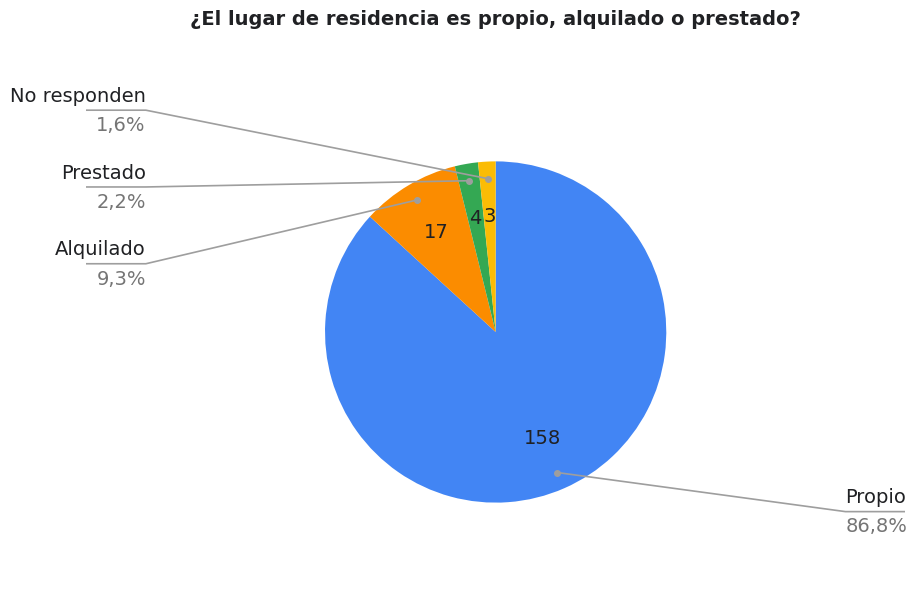

In [70]:
# Ejemplo 1: Gráfico multicategoría con formato exacto Villa Gaucho
categorias_ejemplo = ['Propio', 'Alquilado', 'Prestado', 'No responden']
valores_ejemplo = [158, 17, 4, 3]

graficar_torta(
    categorias=categorias_ejemplo,
    valores=valores_ejemplo,
    titulo="¿El lugar de residencia es propio, alquilado o prestado?"
)


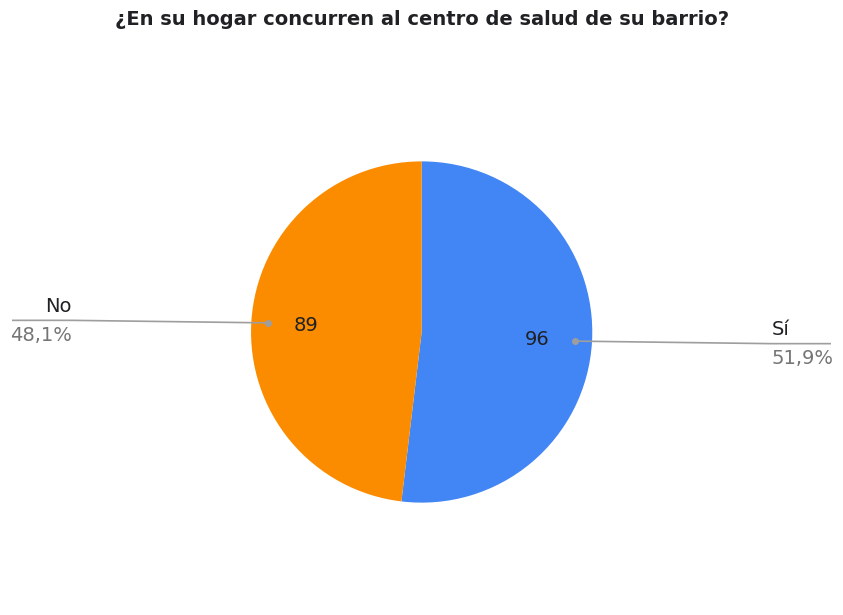

In [71]:
# Ejemplo 2: Pregunta binaria (Positivo = Azul, Negativo = Naranja)
respuestas_binarias = ['Sí', 'No']
frecuencias_binarias = [96, 89]

graficar_torta(
    categorias=respuestas_binarias,
    valores=frecuencias_binarias,
    titulo="¿En su hogar concurren al centro de salud de su barrio?",
    es_binario=True
)


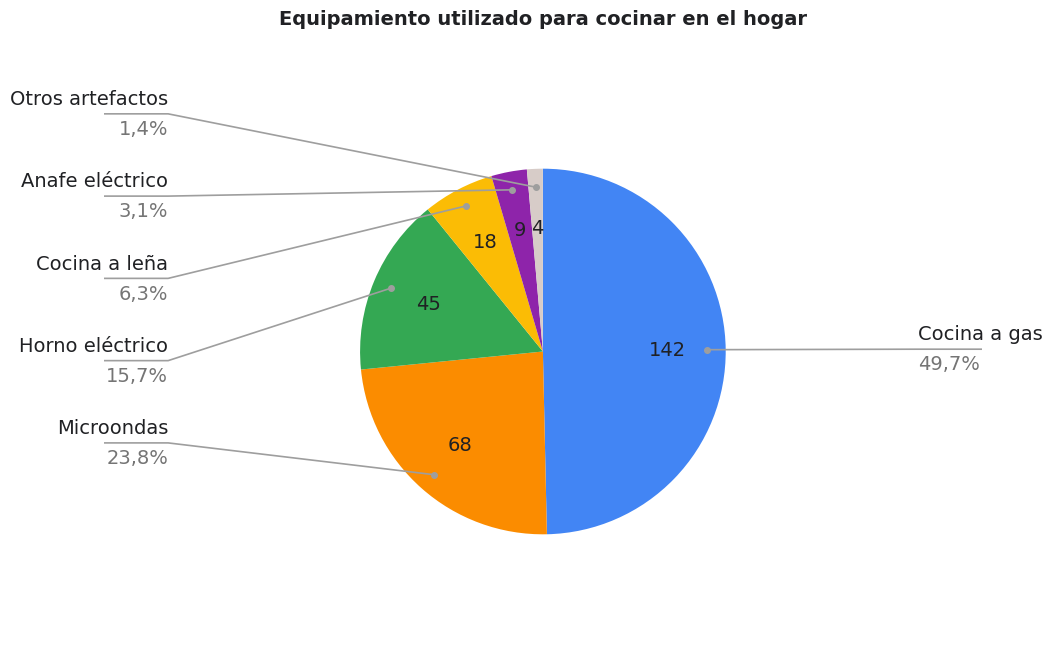

In [72]:
# Ejemplo 3: Torta de 6 opciones balanceada en el recuadro
categorias_6 = [
    'Cocina a gas',
    'Microondas',
    'Horno eléctrico',
    'Cocina a leña',
    'Anafe eléctrico',
    'Otros artefactos'
]
valores_6 = [142, 68, 45, 18, 9, 4]

graficar_torta(
    categorias=categorias_6,
    valores=valores_6,
    titulo="Equipamiento utilizado para cocinar en el hogar",
    figsize=(12, 7.5),
    distancia_etiquetas_y=0.45  # Espaciado vertical óptimo
)


## 2. Gráfico de Barras Estandarizado (Cualitativas y Cuantitativas Discretas)
- **Frecuencia absoluta DENTRO de la barra** en color blanco, negrita y tamaño 14.
- **Color de barras de un solo tono**: **`#1b7882`**.
- Parámetro `usar_colores_torta=True` para usar la paleta de la torta si se requiere diferenciar por categorías.
- Porcentajes a la derecha de cada barra con tamaño 14.


In [73]:
def graficar_barras_horizontales(etiquetas, valores, titulo="", xlabel="Cantidad de respuestas", ylabel="", sufijo_etiqueta="", usar_colores_torta=False, figsize=(12, 6)):
    """
    Genera un gráfico de barras horizontales estandarizado.
    
    Parámetros:
    -----------
    etiquetas : list o pd.Series
        Valores o nombres de las categorías para el eje vertical.
    valores : list o pd.Series
        Frecuencias absolutas de cada categoría.
    titulo : str, opcional
        Título principal del gráfico.
    xlabel : str, por defecto 'Cantidad de respuestas'
        Texto descriptivo para el eje X.
    ylabel : str, opcional
        Texto descriptivo para el eje Y.
    sufijo_etiqueta : str, opcional
        Palabra a agregar al lado de la etiqueta (ej. 'días' o 'personas').
    usar_colores_torta : bool, por defecto False
        Si es True, aplica los colores de la torta (Azul, Naranja, Verde, Amarillo, Violeta, Beige).
        Si es False, utiliza el color institucional #1b7882.
    figsize : tuple, por defecto (12, 6)
        Dimensiones (ancho, alto) de la figura.
    """
    valores = np.array(valores, dtype=float)
    total = np.sum(valores)
    porcentajes = (valores / total) * 100 if total > 0 else np.zeros_like(valores)
    n = len(etiquetas)

    fig, ax = plt.subplots(figsize=figsize)

    # Definir paleta: o un único color (#1b7882) o la paleta de torta
    if usar_colores_torta:
        colores = [PALETA_TORTA[i % len(PALETA_TORTA)] for i in range(n)]
    else:
        colores = COLOR_BARRAS_UNICO

    barras = ax.barh(
        range(n),
        valores,
        color=colores,
        height=0.68,
        edgecolor='none'
    )

    # Etiquetas del eje Y en tamaño 14
    ax.set_yticks(range(n))
    if sufijo_etiqueta:
        labels_y = [f"{lbl} {sufijo_etiqueta}" if int(lbl) != 1 else f"{lbl} {sufijo_etiqueta.rstrip('s')}" for lbl in etiquetas]
    else:
        labels_y = [str(lbl) for lbl in etiquetas]
    ax.set_yticklabels(labels_y, fontsize=14)

    max_val = max(valores) if len(valores) > 0 else 1
    offset_porcentaje = max_val * 0.035

    # ==========================================================================
    # FRECUENCIA ABSOLUTA DENTRO DE LA BARRA Y PORCENTAJES A LA DERECHA
    # ==========================================================================
    for barra, cantidad, porcentaje in zip(barras, valores, porcentajes):
        x = barra.get_width()
        y = barra.get_y() + barra.get_height() / 2.0

        # Número de frecuencia absoluta dentro del cuerpo de la barra
        if x >= max_val * 0.12:
            ax.text(
                x / 2.0, y, str(int(cantidad)),
                ha='center', va='center',
                color='white', fontweight='bold', fontsize=14
            )
        else:
            # Para barras pequeñas, se posiciona cerca del borde interior
            ax.text(
                max(x * 0.65, 0.5), y, str(int(cantidad)),
                ha='center', va='center',
                color='white', fontweight='bold', fontsize=14
            )

        # Porcentaje a la derecha de la barra
        ax.text(
            x + offset_porcentaje, y,
            f"{porcentaje:.1f}%".replace('.', ','),
            ha='left', va='center',
            color='#202124', fontsize=14
        )

    # Títulos y nombres de ejes
    if titulo:
        ax.set_title(titulo, fontsize=14, pad=15, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=14, labelpad=10)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=14, labelpad=10)

    # Escala del eje horizontal y cuadrícula suave
    ax.set_xlim(0, max_val * 1.18)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


### Ejemplos de Gráficos de Barras Horizontales
1. **Ejemplo 1**: Cuantitativa discreta con color único **`#1b7882`** y frecuencia absoluta dentro de cada barra.
2. **Ejemplo 2**: Cualitativa con colores de torta coincidentes (`usar_colores_torta=True`).


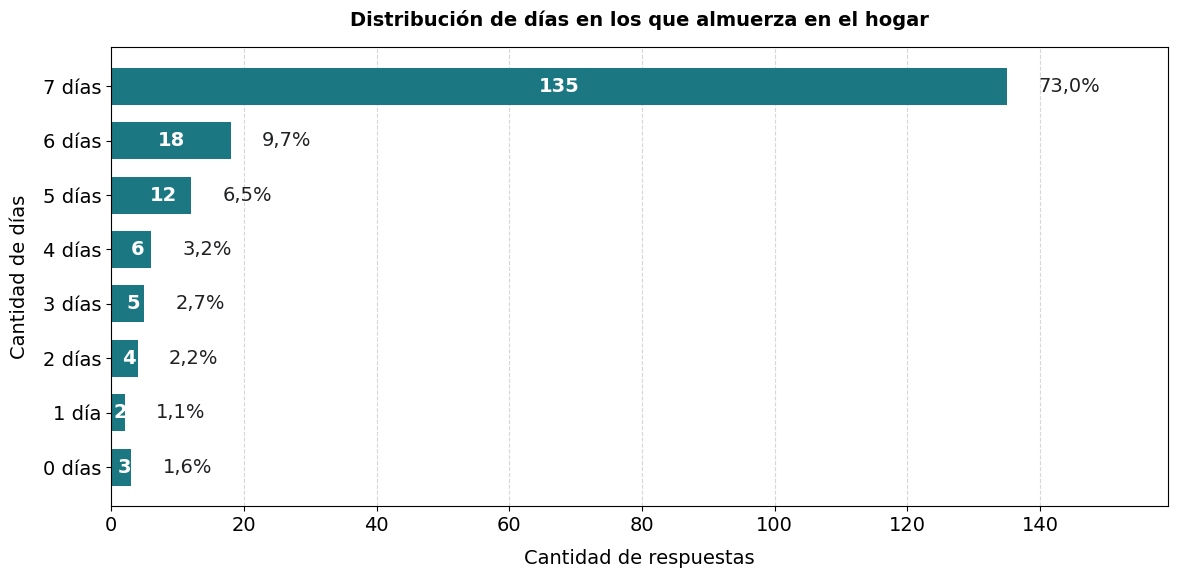

In [74]:
# Ejemplo 1: Variable cuantitativa discreta con color único #1b7882
dias = [0, 1, 2, 3, 4, 5, 6, 7]
respuestas_dias = [3, 2, 4, 5, 6, 12, 18, 135]

graficar_barras_horizontales(
    etiquetas=dias,
    valores=respuestas_dias,
    titulo="Distribución de días en los que almuerza en el hogar",
    xlabel="Cantidad de respuestas",
    ylabel="Cantidad de días",
    sufijo_etiqueta="días",
    usar_colores_torta=False  # Color #1b7882
)


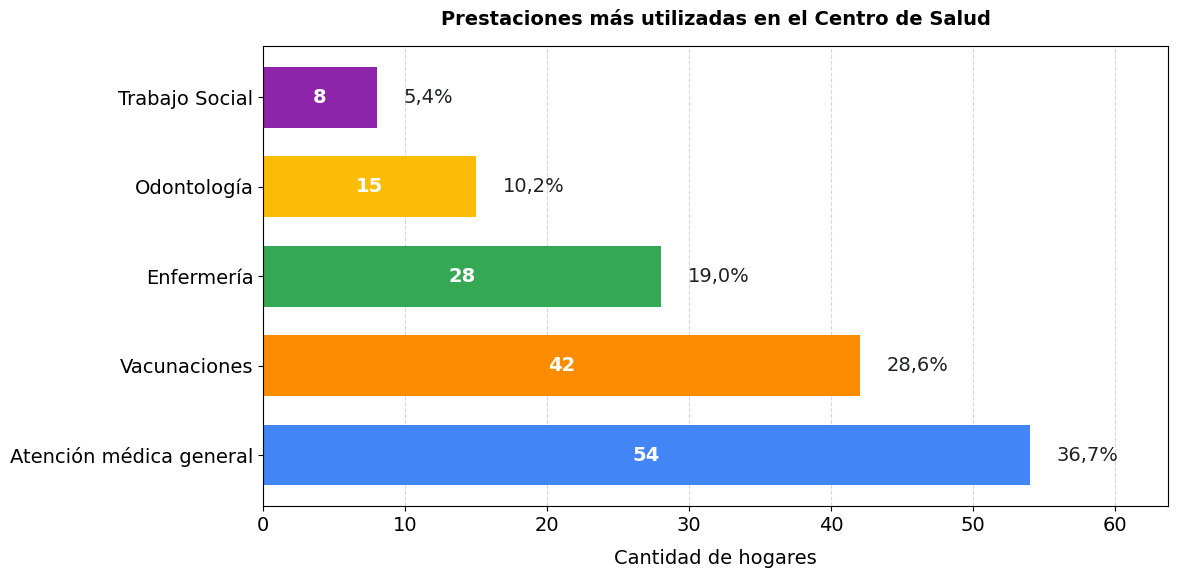

In [75]:
# Ejemplo 2: Variable cualitativa usando los mismos colores que la torta
prestaciones = ['Atención médica general', 'Vacunaciones', 'Enfermería', 'Odontología', 'Trabajo Social']
hogares_prestaciones = [54, 42, 28, 15, 8]

graficar_barras_horizontales(
    etiquetas=prestaciones,
    valores=hogares_prestaciones,
    titulo="Prestaciones más utilizadas en el Centro de Salud",
    xlabel="Cantidad de hogares",
    usar_colores_torta=True  # Mismos colores que la torta: Azul, Naranja, Verde, Amarillo, Violeta
)


## 3. Histograma Continuo para Variables Cuantitativas Continuas (ej. Edad, Ingresos, Tiempo)
Para representar variables cuantitativas continuas con rigor estadístico y el diseño solicitado:
- **Barras continuas unidas** (`width=1.0` o `rwidth=1.0`), **sin separación física entre barras**.
- La separación entre barras no es un espacio en blanco, sino el **borde con el mismo color pero un 40% más oscuro**, con un ancho aproximado de **`0.1`**.
- **Parámetros configurables en la función**:
  - `ancho_borde`: define el grosor de la línea que divide las barras contiguas (por defecto `0.1`).
  - `factor_oscuridad`: porcentaje de oscurecimiento respecto al color base (por defecto `0.40`, es decir, 40% más oscuro).
- Frecuencia absoluta y porcentaje centrados arriba de cada intervalo con fuente tamaño 14.


In [76]:
def graficar_histograma_intervalos(intervalos, frecuencias, titulo="", xlabel="Rango de edad", ylabel="Cantidad de menores", ancho_borde=0.1, factor_oscuridad=0.40, figsize=(10, 6)):
    """
    Genera un histograma continuo (barras unidas sin separación) a partir de rangos/intervalos y frecuencias.
    
    Parámetros configurables:
    -------------------------
    intervalos : list
        Etiquetas de los rangos (ej. ['0 a 2 años', '3 a 5 años', '6 a 11 años', '12 a 18 años']).
    frecuencias : list
        Frecuencia absoluta de cada rango.
    titulo : str, opcional
        Título principal del gráfico.
    xlabel : str, por defecto 'Rango de edad'
        Texto para el eje X.
    ylabel : str, por defecto 'Cantidad de menores'
        Texto para el eje Y.
    ancho_borde : float, por defecto 0.1
        --> PARÁMETRO: Ancho del borde/línea de separación entre barras (aprox 0.1).
    factor_oscuridad : float, por defecto 0.40
        --> PARÁMETRO: Oscuridad del color del borde (0.40 = 40% más oscuro que el color de la barra).
    figsize : tuple, por defecto (10, 6)
        Dimensiones (ancho, alto) de la figura.
    """
    frecuencias = np.array(frecuencias, dtype=float)
    total = sum(frecuencias)
    porcentajes = (frecuencias / total) * 100 if total > 0 else np.zeros_like(frecuencias)
    x_pos = np.arange(len(intervalos))

    fig, ax = plt.subplots(figsize=figsize)

    # Calculamos el color del borde: mismo color pero 40% más oscuro (#10484e)
    color_borde_separacion = oscurecer_color(COLOR_BARRAS_UNICO, factor_oscuridad=factor_oscuridad)

    # width=1.0 elimina la separación física entre barras (continuidad)
    barras = ax.bar(
        x_pos,
        frecuencias,
        width=1.0,                              # Barras continuas pegadas
        color=COLOR_BARRAS_UNICO,                # Color base de la barra (#1b7882)
        edgecolor=color_borde_separacion,       # Borde 40% más oscuro que separa las barras
        linewidth=ancho_borde,                  # Ancho de la línea divisoria (~0.1)
        align='center'
    )

    # Configuración de marcas en el eje X
    ax.set_xticks(x_pos)
    ax.set_xticklabels(intervalos, fontsize=14, rotation=0)

    max_h = max(frecuencias) if len(frecuencias) > 0 else 1

    # Colocamos frecuencia absoluta y porcentaje centrado sobre cada barra (tamaño 14)
    for barra, cant, pct in zip(barras, frecuencias, porcentajes):
        h = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width() / 2.0,
            h + (max_h * 0.02),
            f"{int(cant)}\n({pct:.1f}%)".replace('.', ','),
            ha='center', va='bottom',
            fontsize=14, color='#202124', fontweight='medium'
        )

    # Título y etiquetas de ejes
    if titulo:
        ax.set_title(titulo, fontsize=14, pad=18, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=14, labelpad=10)
    ax.set_ylabel(ylabel, fontsize=14, labelpad=10)

    # Escalas y límites
    ax.set_ylim(0, max_h * 1.25)
    ax.set_xlim(-0.5, len(intervalos) - 0.5)

    # Cuadrícula horizontal suave
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


In [77]:
def graficar_histograma_datos_crudos(datos, bins=5, titulo="", xlabel="Edad", ylabel="Frecuencia", ancho_borde=0.1, factor_oscuridad=0.40, figsize=(10, 6)):
    """
    Genera un histograma continuo directamente desde una serie o lista de valores numéricos continuos.
    
    Parámetros configurables:
    -------------------------
    datos : list, np.array o pd.Series
        Valores continuos (ej. edades, ingresos).
    bins : int o list, por defecto 5
        Cantidad de intervalos o límites de intervalos.
    ancho_borde : float, por defecto 0.1
        --> PARÁMETRO: Ancho del borde/separación entre barras (aprox 0.1).
    factor_oscuridad : float, por defecto 0.40
        --> PARÁMETRO: Oscuridad del color del borde (0.40 = 40% más oscuro).
    """
    datos_limpios = pd.Series(datos).dropna().values
    total = len(datos_limpios)

    fig, ax = plt.subplots(figsize=figsize)

    # Color del borde 40% más oscuro que el color de la barra
    color_borde_separacion = oscurecer_color(COLOR_BARRAS_UNICO, factor_oscuridad=factor_oscuridad)

    # Histograma continuo con ax.hist (rwidth=1.0)
    counts, bin_edges, patches = ax.hist(
        datos_limpios,
        bins=bins,
        color=COLOR_BARRAS_UNICO,          # Color #1b7882
        edgecolor=color_borde_separacion,  # Borde 40% más oscuro
        linewidth=ancho_borde,              # Ancho del borde (~0.1)
        rwidth=1.0                         # Continuo sin separación física
    )

    max_h = max(counts) if len(counts) > 0 else 1

    # Anotaciones de frecuencia y porcentaje centradas arriba de cada barra
    for patch, count in zip(patches, counts):
        if count > 0:
            pct = (count / total) * 100
            x = patch.get_x() + patch.get_width() / 2.0
            h = patch.get_height()
            ax.text(
                x, h + (max_h * 0.02),
                f"{int(count)}\n({pct:.1f}%)".replace('.', ','),
                ha='center', va='bottom',
                fontsize=14, color='#202124', fontweight='medium'
            )

    # Marcas del eje X en los límites de cada intervalo
    ax.set_xticks(bin_edges)
    ax.set_xticklabels([f"{b:.0f}" for b in bin_edges], fontsize=14)

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=18, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=14, labelpad=10)
    ax.set_ylabel(ylabel, fontsize=14, labelpad=10)

    ax.set_ylim(0, max_h * 1.25)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


### Ejemplos de Histogramas Continuos
1. **Ejemplo 1**: Con intervalos ya agrupados (como en la encuesta: 0 a 2 años, 3 a 5 años, etc.) con borde 40% más oscuro y ancho 0.1.
2. **Ejemplo 2**: Con datos crudos numéricos continuos agrupados en bins contiguos.


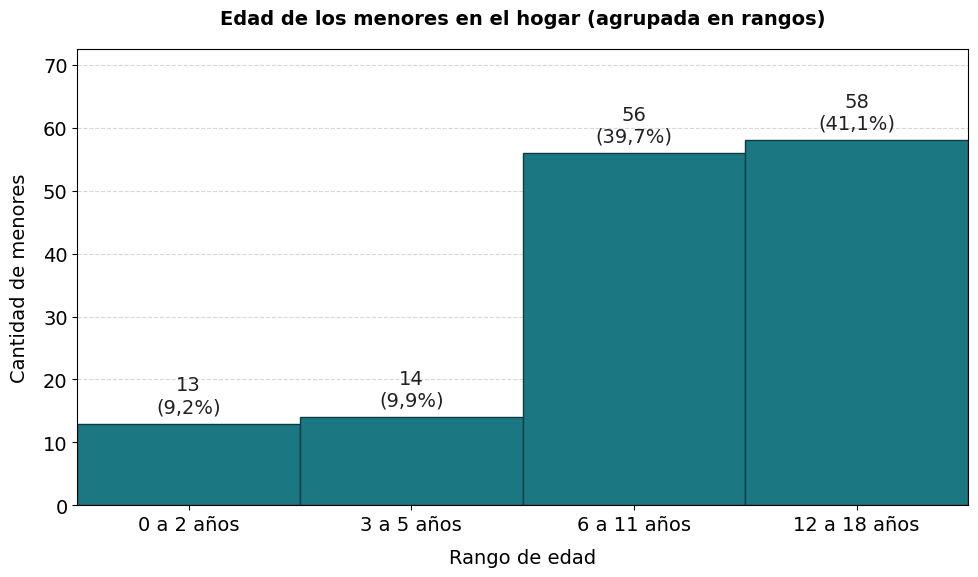

In [81]:
# Ejemplo 1: Histograma continuo con rangos de edad (barras continuas unidas)
# Parámetros indicados: ancho_borde=0.1, factor_oscuridad=0.40
rangos_edad = ['0 a 2 años', '3 a 5 años', '6 a 11 años', '12 a 18 años']
cantidades_menores = [13, 14, 56, 58]

graficar_histograma_intervalos(
    intervalos=rangos_edad,
    frecuencias=cantidades_menores,
    titulo="Edad de los menores en el hogar (agrupada en rangos)",
    xlabel="Rango de edad",
    ylabel="Cantidad de menores",
    ancho_borde=1.0,         # Ancho de la línea entre barras (aprox 0.1)
    factor_oscuridad=0.50    # Color del borde 40% más oscuro
)


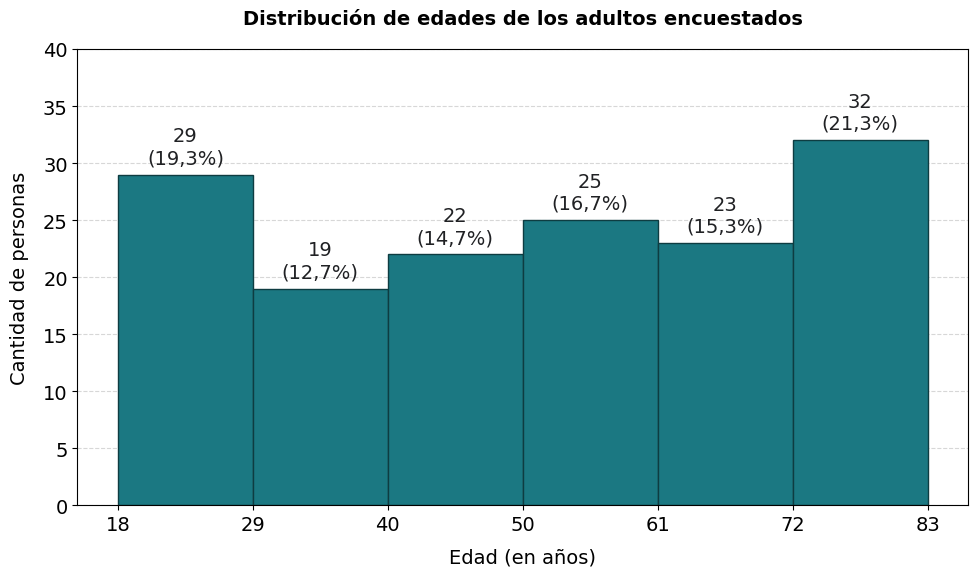

In [82]:
# Ejemplo 2: Histograma continuo a partir de datos numéricos continuos
# Simulamos una serie de edades de personas encuestadas
np.random.seed(42)
edades_ejemplo = np.random.randint(18, 85, size=150)

graficar_histograma_datos_crudos(
    datos=edades_ejemplo,
    bins=6,
    titulo="Distribución de edades de los adultos encuestados",
    xlabel="Edad (en años)",
    ylabel="Cantidad de personas",
    ancho_borde=1.0,         # Ancho de la línea entre barras
    factor_oscuridad=0.50    # Color del borde 40% más oscuro
)


## 4. Integración y uso directo con `datos.csv`
Ejemplo de procesamiento directo de datos del repositorio con el formato final.


Dataset cargado correctamente. Registros: 52 | Columnas: 342

Frecuencias obtenidas:
1.7 Habitualmente cuando se cocina en el hogar, ¿se le agrega sal a las comidas durante la cocción?
Sí    45
No     7
Name: count, dtype: int64


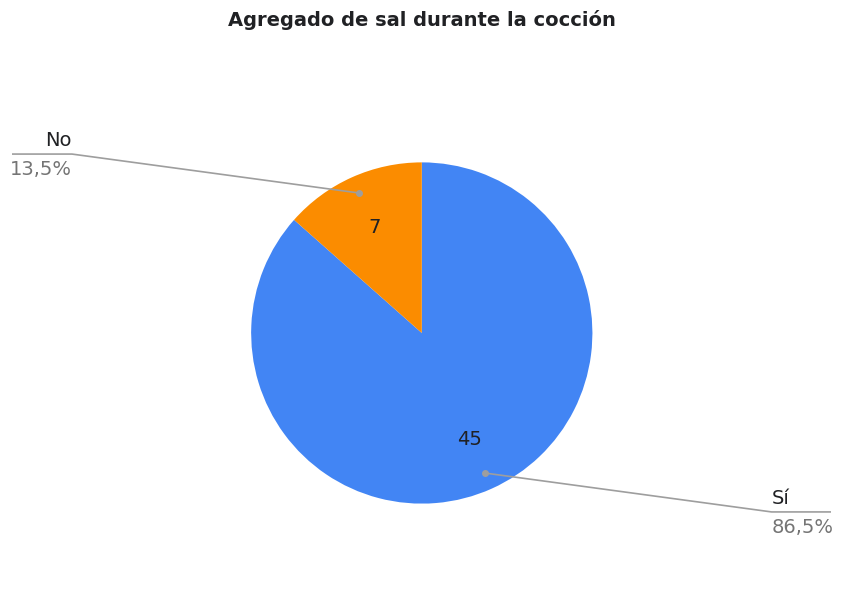

In [80]:
# ==============================================================================
# EJEMPLO CON DATOS REALES DE 'datos.csv'
# ==============================================================================
try:
    df_datos = pd.read_csv('datos.csv')
    print("Dataset cargado correctamente. Registros:", len(df_datos), "| Columnas:", len(df_datos.columns))

    col_sal = '1.7 Habitualmente cuando se cocina en el hogar, ¿se le agrega sal a las comidas durante la cocción?'
    if col_sal in df_datos.columns:
        conteo_sal = df_datos[col_sal].value_counts()
        print("\nFrecuencias obtenidas:")
        print(conteo_sal)

        # Graficamos la pregunta binaria con el nuevo formato optimizado
        graficar_torta(
            categorias=conteo_sal.index,
            valores=conteo_sal.values,
            titulo="Agregado de sal durante la cocción",
            es_binario=True
        )
except FileNotFoundError:
    print("Asegurate de que 'datos.csv' se encuentre en la misma carpeta del cuaderno.")
